# Kto wygra mecz ATP? Część 1: dane i cechy

**Projekt SRD (SGH, semestr zimowy 2026/27).**

**Cel projektu:** przewidzieć **przed rozpoczęciem meczu**, który z dwóch zawodników wygra mecz ATP, i sprawdzić, czy model uczenia maszynowego bije prostą regułę „wygrywa wyżej notowany w rankingu”.

**Cel tego notatnika:** przygotować zbiór danych, na którym trenujemy modele. Na wyjściu dostajemy plik `dane/atp_cechy_2015_2024.csv`:
* jeden wiersz = jeden mecz ATP z lat 2015–2024,
* zmienna celu `A_wins` (1 = wygrał zawodnik A, 0 = wygrał zawodnik B),
* cechy policzone **wyłącznie z informacji dostępnych przed meczem**.

**Źródło danych:** Jeff Sackmann, [tennis_atp](https://github.com/JeffSackmann/tennis_atp) (licencja CC BY-NC-SA 4.0), pobierane z archiwalnej kopii [tennis-sackmann-archive](https://github.com/kaniosola-pixel/tennis-sackmann-archive).

**Plan notatnika:**
1. Wczytanie danych (2010–2024; lata 2010–2014 służą tylko jako „rozgrzewka” historii graczy).
2. Czyszczenie: kolejność meczów, duplikaty, krecze i walkowery, braki, wartości odstające.
3. Cechy historyczne w układzie „zawodnik–mecz” (`shift(1)`, czyli tylko przeszłość).
4. Ranking Elo liczony sekwencyjnie.
5. Losowe przypisanie ról A/B.
6. Podział czasowy, imputacja braków i cechy „A minus B”.
7. Kontrole jakości i testy na wyciek danych.
8. Zapis gotowego zbioru.
9. Podsumowanie i wnioski.

## 0. Biblioteki i ustawienia

Jeśli brakuje pakietów, w osobnej komórce uruchom `%pip install --upgrade numpy pandas matplotlib seaborn scikit-learn` i zrestartuj kernel.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, roc_auc_score

pd.set_option("display.max_columns", 60)   # pokazuj do 60 kolumn w podglądzie tabel
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42              # ziarno losowości, żeby wyniki były powtarzalne
FIRST_HISTORY_YEAR = 2010      # od kiedy liczymy historię graczy (rozgrzewka cech i Elo)
FIRST_MODEL_YEAR = 2015        # od kiedy mecze trafiają do zbioru modelowego
LAST_TRAIN_YEAR = 2022         # trening: 2015–2022, test: 2023–2024
LAST_YEAR = 2024

Pliki z meczami pobieramy z GitHuba do folderu `atp` obok notatnika. Jeśli notatnik leży w repozytorium z danymi (folder `../atp` już istnieje), korzystamy z niego i niczego nie pobieramy.

In [2]:
BASE_URL = "https://raw.githubusercontent.com/kaniosola-pixel/tennis-sackmann-archive/main/atp"
DATA_DIR = "../atp" if os.path.isdir("../atp") else "atp"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs("dane", exist_ok=True)                 # tu zapiszemy gotowy zbiór

for year in range(FIRST_HISTORY_YEAR, LAST_YEAR + 1):
    fname = f"atp_matches_{year}.csv"
    if not os.path.exists(f"{DATA_DIR}/{fname}"):  # pobieramy tylko brakujące pliki
        urllib.request.urlretrieve(f"{BASE_URL}/{fname}", f"{DATA_DIR}/{fname}")
print("Dane w folderze:", DATA_DIR, "| liczba plików:", len(os.listdir(DATA_DIR)))

Dane w folderze: ../atp | liczba plików: 176


## 1. Wczytanie danych

Każdy plik to jeden sezon, więc łączymy je przez `pd.concat`. Kolumna `tourney_date` ma format RRRRMMDD i oznacza **dzień rozpoczęcia turnieju**, a nie dzień meczu. Wszystkie mecze turnieju mają więc tę samą datę, co trzeba uwzględnić przy ustalaniu kolejności (punkt 2.1).

In [3]:
raw = pd.concat(
    [pd.read_csv(f"{DATA_DIR}/atp_matches_{year}.csv") for year in range(FIRST_HISTORY_YEAR, LAST_YEAR + 1)],
    ignore_index=True,   # nowy indeks 0..n-1 zamiast powtarzających się indeksów z plików
)
# 20150104 -> 2015-01-04
raw["tourney_date"] = pd.to_datetime(raw["tourney_date"].astype(str), format="%Y%m%d")
raw["year"] = raw["tourney_date"].dt.year
print(raw.shape)
raw.head()

(42571, 50)


,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points,year
0,2010-339,Brisbane,Hard,32,A,2010-01-03,1,104053,1.0,NaN,Andy Roddick,R,188.0,USA,27.3,103429,NaN,NaN,Peter Luczak,R,183.0,AUS,30.3,7-6(5) 6-2,3,R32,84.0,15.0,0.0,63.0,42.0,36.0,14.0,10.0,3.0,3.0,4.0,2.0,56.0,34.0,29.0,11.0,10.0,3.0,5.0,7.0,4410.0,77.0,598.0,2010
1,2010-339,Brisbane,Hard,32,A,2010-01-03,2,104958,NaN,WC,Carsten Ball,L,198.0,AUS,22.5,104999,NaN,NaN,Mischa Zverev,L,190.0,GER,22.3,7-5 6-1,3,R32,70.0,10.0,3.0,57.0,30.0,23.0,19.0,10.0,0.0,0.0,2.0,2.0,66.0,34.0,22.0,14.0,9.0,7.0,10.0,134.0,400.0,78.0,590.0,2010
2,2010-339,Brisbane,Hard,32,A,2010-01-03,3,104755,NaN,NaN,Richard Gasquet,R,185.0,FRA,23.5,103813,NaN,NaN,Jarkko Nieminen,L,185.0,FIN,28.4,6-3 4-6 6-4,3,R32,121.0,5.0,4.0,97.0,51.0,33.0,27.0,15.0,5.0,8.0,4.0,0.0,85.0,58.0,38.0,14.0,14.0,7.0,11.0,52.0,850.0,88.0,568.0,2010
3,2010-339,Brisbane,Hard,32,A,2010-01-03,4,105051,NaN,Q,Matthew Ebden,R,188.0,AUS,22.1,103781,6.0,NaN,Jurgen Melzer,L,183.0,AUT,28.6,7-5 6-1,3,R32,64.0,12.0,1.0,50.0,35.0,30.0,12.0,10.0,3.0,3.0,2.0,1.0,53.0,29.0,16.0,15.0,9.0,2.0,5.0,285.0,151.0,28.0,1260.0,2010
4,2010-339,Brisbane,Hard,32,A,2010-01-03,5,104607,4.0,NaN,Tomas Berdych,R,196.0,CZE,24.2,105194,NaN,Q,Nick Lindahl,R,183.0,AUS,21.4,6-2 6-4,3,R32,69.0,3.0,1.0,46.0,27.0,24.0,14.0,9.0,1.0,1.0,6.0,1.0,69.0,41.0,26.0,14.0,9.0,6.0,9.0,20.0,1655.0,251.0,179.0,2010


In [4]:
raw.groupby("year").size().to_frame("liczba_meczow").T

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
liczba_meczow,3030,3015,3094,2944,2816,2943,2941,2911,2982,2721,1462,2733,2917,2986,3076


**Wynik:** 42 571 meczów i 49 oryginalnych kolumn (plus dopisana `year`). Sezony mają po ok. 2 700–3 100 meczów, wyjątkiem jest 2020 r. (pandemia, 1 462 mecze). Same lata 2015–2024 to 27 672 mecze, więc wymóg >5000 rekordów jest spełniony z dużym zapasem.

## 2. Czyszczenie

### 2.1 Kolejność meczów

Cechy historyczne (forma, Elo) wymagają poprawnej kolejności meczów. Ponieważ data jest wspólna dla całego turnieju, w obrębie turnieju sortujemy po rundzie (od 1. rundy do finału), a w rundzie po `match_num`.

* `RR` (round robin) to faza grupowa w ATP Finals i Pucharze Davisa, więc stawiamy ją przed ćwierćfinałem.
* `BR` (bronze) to mecz o brązowy medal olimpijski, rozgrywany między półfinałem a finałem.

In [5]:
ROUND_ORDER = {"R128": 1, "R64": 2, "R32": 3, "R16": 4, "RR": 4.5, "QF": 5, "SF": 6, "BR": 6.5, "F": 7}
raw["round_order"] = raw["round"].map(ROUND_ORDER)
print("Nieznane rundy:", raw["round_order"].isna().sum())   # kontrola: każda runda ma numer

matches = (
    raw.sort_values(["tourney_date", "tourney_id", "round_order", "match_num"])
    .reset_index(drop=True)
)
matches["match_id"] = np.arange(len(matches))   # globalny numer meczu = oś czasu (mniejszy = wcześniejszy)

Nieznane rundy: 0


### 2.2 Duplikaty

Mecz jest jednoznacznie identyfikowany przez turniej (`tourney_id`) i numer meczu w turnieju (`match_num`).

In [6]:
print("Duplikaty (tourney_id, match_num):", matches.duplicated(subset=["tourney_id", "match_num"]).sum())

Duplikaty (tourney_id, match_num): 0


**Wynik:** brak duplikatów, nic nie usuwamy.

### 2.3 Mecze niedokończone

W kolumnie `score` szukamy kreczów (`RET`), walkowerów (`W/O`, `Walkover`), dyskwalifikacji (`DEF`, `Def.`, `Default`) i meczów przerwanych (`ABD`, `abandoned`).

Rozróżniamy dwie sytuacje:
* **Do zbioru modelowego** bierzemy tylko mecze dokończone. Przy kreczu wynik nie mówi, kto grał lepiej, bo zawodnik mógł prowadzić i doznać kontuzji.
* **Do historii gracza** (forma, Elo, H2H) bierzemy wszystkie mecze faktycznie rozegrane, także te z kreczem. Pomijamy tylko walkowery, bo wtedy mecz się nie odbył.

In [7]:
score = matches["score"].astype(str)
# dwie flagi True/False: na razie niczego nie usuwamy
matches["walkover"] = score.str.contains(r"W/O|Walkover", case=False)
matches["unfinished"] = score.str.contains(r"RET|W/O|Walkover|DEF|Def\.|Default|ABD|abandoned", case=False)

in_model_years = matches["year"].between(FIRST_MODEL_YEAR, LAST_YEAR)
print("Mecze 2015–2024:", in_model_years.sum())
print("w tym niedokończone:", (in_model_years & matches["unfinished"]).sum())
print("Zostaje do modelu:", (in_model_years & ~matches["unfinished"]).sum())

Mecze 2015–2024: 27672
w tym niedokończone: 913
Zostaje do modelu: 26759


**Wynik:** 913 meczów niedokończonych (3,3%), do modelu zostaje 26 759 meczów.

### 2.4 Braki danych w kolumnach przedmeczowych

In [8]:
pre_match_cols = ["winner_rank", "loser_rank", "winner_rank_points", "loser_rank_points",
                  "winner_ht", "loser_ht", "winner_age", "loser_age", "surface", "w_svpt", "l_svpt"]
# odsetek braków w każdej kolumnie, w procentach
(matches.loc[in_model_years, pre_match_cols].isna().mean() * 100).round(2).to_frame("% braków")

,% braków
winner_rank,0.50
loser_rank,1.28
winner_rank_points,0.50
loser_rank_points,1.28
winner_ht,0.64
loser_ht,1.67
winner_age,0.01
loser_age,0.01
surface,0.19
w_svpt,3.91


**Wynik:** braków jest niewiele. Przegrani mają ich więcej niż zwycięzcy, bo to częściej słabsi, mniej znani gracze, więc **sam brak też niesie informację** (dlatego przy imputacji dodamy flagi braku). Statystyk serwisowych (`w_svpt`, `l_svpt`) brakuje w ok. 4% meczów, głównie w Pucharze Davisa.

Braków nie uzupełniamy jeszcze teraz. Zrobimy to w punkcie 6, po podziale na trening i test, żeby mediany liczyć **tylko na zbiorze treningowym** (unikamy wycieku informacji z testu).

### 2.5 Wartości odstające

Wiek i wzrost sprawdzamy regułą IQR: podejrzana jest wartość spoza przedziału $[Q_1 - 3 \cdot IQR,\ Q_3 + 3 \cdot IQR]$. Używamy mnożnika 3 zamiast typowego 1,5, bo przy 1,5 górna granica wzrostu wynosiłaby ok. 203 cm i odcięłaby prawdziwych, bardzo wysokich zawodników (np. Opelka, 211 cm).

Ranking i punkty rankingowe są silnie skośne, ale to prawdziwe wartości, więc ich nie usuwamy, tylko logarytmujemy przy budowie cech (punkt 6).

In [9]:
for col in ["ht", "age"]:
    values = pd.concat([matches[f"winner_{col}"], matches[f"loser_{col}"]])   # wszyscy gracze razem
    q1, q3 = values.quantile([0.25, 0.75])
    low, high = q1 - 3 * (q3 - q1), q3 + 3 * (q3 - q1)
    for role in ["winner", "loser"]:
        bad = ~matches[f"{role}_{col}"].between(low, high) & matches[f"{role}_{col}"].notna()
        print(f"{role}_{col}: zakres [{low:.1f}, {high:.1f}], poza zakresem: {bad.sum()} -> {sorted(matches.loc[bad, f'{role}_{col}'].unique())}")
        if col == "ht":
            matches.loc[bad, f"{role}_{col}"] = np.nan   # błąd wprowadzania -> brak, uzupełnimy później

winner_ht: zakres [159.0, 215.0], poza zakresem: 5 -> [np.float64(3.0), np.float64(15.0), np.float64(71.0)]
loser_ht: zakres [159.0, 215.0], poza zakresem: 6 -> [np.float64(3.0), np.float64(15.0), np.float64(71.0)]
winner_age: zakres [6.4, 47.7], poza zakresem: 0 -> []
loser_age: zakres [6.4, 47.7], poza zakresem: 0 -> []


**Wynik:** wzrost 3, 15 i 71 cm to oczywiste błędy wprowadzania danych (11 wystąpień), więc zamieniamy je na brak. Wiek nie ma wartości odstających.

### 2.6 Nawierzchnia

Dywan (`Carpet`, kilkadziesiąt meczów do 2016 r.) i brak nawierzchni łączymy w jedną kategorię `Other`, bo tak małe grupy nic nie wniosą do modelu.

In [10]:
matches["surface"] = matches["surface"].where(matches["surface"].isin(["Hard", "Clay", "Grass"]), "Other")
matches["surface"].value_counts()

surface
Hard     24793
Clay     13142
Grass     4517
Other      119
Name: count, dtype: int64

## 3. Cechy historyczne: układ „zawodnik–mecz”

Surowy wiersz opisuje mecz z perspektywy zwycięzcy i przegranego. Żeby policzyć historię **jednego zawodnika** (np. jego formę), rozkładamy każdy mecz na dwa wiersze: jeden dla zwycięzcy (`win = 1`), drugi dla przegranego (`win = 0`). Wtedy wystarczy `groupby("player_id")`.

Przy okazji liczymy statystyki z danego meczu, które **same w sobie są wyciekiem** (znamy je dopiero po meczu), ale ich średnia z **poprzednich** meczów jest legalną cechą:
* `serve_won` = odsetek punktów wygranych przy własnym serwisie = (wygrane po 1. serwisie + wygrane po 2. serwisie) / punkty serwisowe,
* `return_won` = odsetek punktów wygranych przy serwisie rywala = 1 − odsetek wygranych serwisowych rywala.

In [11]:
played = matches[~matches["walkover"]].copy()   # historia: wszystkie rozegrane mecze (bez walkowerów)


def player_rows(df, me, opp, win):
    """Jeden wiersz na zawodnika `me` w każdym meczu (me/opp to prefiksy 'winner'/'loser')."""
    # statystyki zwycięzcy mają prefiks w_, przegranego l_; dla przegranego zamieniamy je miejscami
    s_me, s_opp = ("w", "l") if me == "winner" else ("l", "w")
    return pd.DataFrame({
        "match_id": df["match_id"],
        "tourney_id": df["tourney_id"],
        "tourney_date": df["tourney_date"],
        "surface": df["surface"],
        "player_id": df[f"{me}_id"],
        "opp_id": df[f"{opp}_id"],
        "win": win,
        "serve_won": (df[f"{s_me}_1stWon"] + df[f"{s_me}_2ndWon"]) / df[f"{s_me}_svpt"],
        "return_won": 1 - (df[f"{s_opp}_1stWon"] + df[f"{s_opp}_2ndWon"]) / df[f"{s_opp}_svpt"],
    })


long = pd.concat([player_rows(played, "winner", "loser", 1),
                  player_rows(played, "loser", "winner", 0)])
long = long.replace([np.inf, -np.inf], np.nan)                       # svpt = 0 daje dzielenie przez zero
long = long.sort_values(["player_id", "match_id"]).reset_index(drop=True)   # gracz, potem chronologicznie
print(long.shape)
long.head()

(84612, 9)


,match_id,tourney_id,tourney_date,surface,player_id,opp_id,win,serve_won,return_won
0,10977,2013-414,2013-07-15,Clay,100644,105138,0,0.333333,0.392857
1,13213,2014-308,2014-04-28,Clay,100644,103781,0,0.386364,0.297872
2,13887,2014-321,2014-07-07,Clay,100644,104586,0,0.634409,0.313953
3,13914,2014-414,2014-07-14,Clay,100644,104898,1,0.727273,0.576923
4,13930,2014-414,2014-07-14,Clay,100644,104022,1,0.623377,0.465116


**Wynik:** 84 612 wierszy, czyli 42 306 rozegranych meczów × 2 zawodników.

### 3.1 Kluczowy trik: `shift(1)`

W każdej grupie (zawodnik) przesuwamy kolumnę o jeden wiersz w dół. Wartość w wierszu meczu *t* pochodzi wtedy z meczu *t − 1*, więc **wynik bieżącego meczu nigdy nie trafia do jego własnej cechy**. Dopiero na przesuniętej kolumnie liczymy średnią kroczącą (`rolling`) albo sumę narastającą (`cumsum`).

| Cecha | Definicja |
|---|---|
| `n_prev` | liczba wcześniejszych meczów gracza od 2010 r. (miara „zimnego startu”) |
| `form10` | odsetek wygranych w ostatnich 10 meczach |
| `serve_avg`, `return_avg` | średni `serve_won` / `return_won` z ostatnich 20 meczów (min. 3 mecze ze statystykami) |
| `surface_wr` | odsetek wygranych w ostatnich 20 meczach **na tej nawierzchni**, wygładzony |
| `h2h_wins`, `h2h_n` | wygrane i liczba wcześniejszych meczów z **tym samym rywalem** |

**Wygładzanie `surface_wr`:** do prawdziwych meczów doliczamy 5 „wirtualnych” meczów z wynikiem 50%. Gracz z bilansem 1–0 na trawie dostaje (1 + 2,5) / (1 + 5) ≈ 58% zamiast 100%, a przy wielu meczach wygładzenie przestaje mieć znaczenie.

In [12]:
g = long.groupby("player_id")

long["n_prev"] = g.cumcount()   # numeracja od 0: w pierwszym meczu gracz ma 0 wcześniejszych
long["form10"] = g["win"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
long["serve_avg"] = g["serve_won"].transform(lambda s: s.shift(1).rolling(20, min_periods=3).mean())
long["return_avg"] = g["return_won"].transform(lambda s: s.shift(1).rolling(20, min_periods=3).mean())

# odsetek wygranych na nawierzchni, wygładzony: (wygrane + 5 * 0.5) / (mecze + 5)
PRIOR_N = 5
gs = long.groupby(["player_id", "surface"])["win"]
surf_wins = gs.transform(lambda s: s.shift(1).rolling(20, min_periods=1).sum()).fillna(0)
surf_n = gs.transform(lambda s: s.shift(1).rolling(20, min_periods=1).count()).fillna(0)
long["surface_wr"] = (surf_wins + PRIOR_N * 0.5) / (surf_n + PRIOR_N)
long["surface_n_prev"] = long.groupby(["player_id", "surface"]).cumcount()

# head-to-head: grupujemy po parze (zawodnik, rywal)
gh = long.groupby(["player_id", "opp_id"])["win"]
long["h2h_wins"] = gh.transform(lambda s: s.shift(1).cumsum()).fillna(0)
long["h2h_n"] = long.groupby(["player_id", "opp_id"]).cumcount()

long[["n_prev", "form10", "surface_wr", "h2h_wins", "h2h_n", "serve_avg", "return_avg"]].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
n_prev,84612.0,164.731,162.955,0.000,37.000,113.000,245.000,995.000
form10,82975.0,0.508,0.205,0.000,0.400,0.500,0.600,1.000
surface_wr,84612.0,0.519,0.122,0.119,0.420,0.500,0.583,0.900
h2h_wins,84612.0,0.537,1.266,0.000,0.000,0.000,1.000,23.000
h2h_n,84612.0,1.074,2.103,0.000,0.000,0.000,1.000,38.000
serve_avg,79047.0,0.638,0.040,0.288,0.610,0.637,0.664,0.814
return_avg,79048.0,0.366,0.035,0.161,0.343,0.365,0.387,0.570


**Wynik:** średnia `form10` i `surface_wr` jest bliska 0,5, czego się spodziewamy (każdy mecz ma jednego zwycięzcę i jednego przegranego). `form10` ma braki tylko w pierwszym meczu gracza w danych (uzupełnimy je neutralną wartością 0,5). `h2h_n` ma medianę 0, bo większość par gra ze sobą po raz pierwszy.

### 3.2 Zmęczenie i przerwa

* `days_since_last_tourney` to przerwa od poprzedniego turnieju w dniach. Nie liczymy „dni od poprzedniego meczu”, bo wszystkie mecze turnieju mają tę samą datę i w turnieju zawsze wychodziłoby 0. Bierzemy więc jeden wiersz na parę (gracz, turniej) i liczymy różnicę dat startu kolejnych turniejów.
* `matches_14d` to liczba **wcześniejszych** meczów gracza w ostatnich 14 dniach, łącznie z wcześniejszymi rundami bieżącego turnieju (gracz w finale ma tu kilka meczów). Daty gracza są posortowane, więc `np.searchsorted` znajduje pozycję pierwszego meczu w 14-dniowym oknie, a różnica pozycji daje liczbę meczów.

In [13]:
tour = long.drop_duplicates(["player_id", "tourney_id"])[["player_id", "tourney_id", "tourney_date"]].copy()
tour["days_since_last_tourney"] = tour.groupby("player_id")["tourney_date"].diff().dt.days
long = long.merge(tour[["player_id", "tourney_id", "days_since_last_tourney"]],
                  on=["player_id", "tourney_id"], how="left")   # przerwa trafia do wszystkich meczów turnieju


def matches_last_14d(dates):
    """Dla każdego meczu: ile wcześniejszych meczów gracza ma datę turnieju nie starszą niż 14 dni."""
    d = dates.values
    first_in_window = np.searchsorted(d, d - np.timedelta64(14, "D"), side="left")
    return pd.Series(np.arange(len(d)) - first_in_window, index=dates.index)


long = long.sort_values(["player_id", "match_id"]).reset_index(drop=True)
long["matches_14d"] = long.groupby("player_id", group_keys=False)["tourney_date"].apply(matches_last_14d)

print(long.shape)
long[["days_since_last_tourney", "matches_14d"]].describe().T.round(3)

(84612, 19)


,count,mean,std,min,25%,50%,75%,max
days_since_last_tourney,82408.0,41.782,121.837,0.0,7.0,14.0,25.0,3255.0
matches_14d,84612.0,2.330,2.193,0.0,1.0,2.0,4.0,15.0


**Wynik:** typowa przerwa między turniejami to 2 tygodnie (mediana 14 dni). Maksimum ponad 3000 dni to powroty po wieloletniej przerwie, dlatego w cechach obetniemy przerwę do 365 dni.

## 4. Ranking Elo

Elo to alternatywa dla rankingu ATP, znana z szachów. Każdy gracz startuje z 1500 punktami, a po każdym meczu zwycięzca zabiera przegranemu część punktów: tym więcej, im bardziej wygrana była niespodziewana. Oczekiwane prawdopodobieństwo wygranej A:

$$P(A) = \frac{1}{1 + 10^{(Elo_B - Elo_A)/400}}$$

Po meczu Elo zwycięzcy rośnie o $K \cdot (1 - P)$, gdzie $1 - P$ to „stopień zaskoczenia”. Współczynnik $K$ maleje z liczbą rozegranych meczów (wariant FiveThirtyEight: $K = 250 / (n + 5)^{0.4}$), więc nowi gracze szybko „znajdują” swój poziom, a doświadczeni są stabilniejsi. Liczymy też osobne Elo dla każdej nawierzchni, bo np. specjalista od mączki może być dużo słabszy na trawie.

**Kolejność jest kluczowa:** do cechy zapisujemy Elo **przed** meczem, a dopiero potem je aktualizujemy. Lata 2010–2014 to rozgrzewka, żeby w 2015 r. wartości były już stabilne.

Używamy zwykłej pętli zamiast `groupby`, bo Elo w meczu zależy od Elo **obu** graczy z ich wcześniejszych meczów, więc nie da się go policzyć jedną operacją wektorową.

In [14]:
def compute_elo(df):
    elo, elo_surf = {}, {}                 # aktualne Elo: gracz -> wartość, (gracz, nawierzchnia) -> wartość
    n_played, n_played_surf = {}, {}       # liczba rozegranych meczów (do współczynnika K)
    rows = []
    for m in df.itertuples(index=False):   # mecze w kolejności chronologicznej
        w, l, s = m.winner_id, m.loser_id, m.surface
        ew, el = elo.get(w, 1500.0), elo.get(l, 1500.0)
        sw, sl = elo_surf.get((w, s), 1500.0), elo_surf.get((l, s), 1500.0)
        rows.append((m.match_id, ew, el, sw, sl))       # zapis PRZED aktualizacją (brak wycieku)

        # Elo ogólne
        p_w = 1 / (1 + 10 ** ((el - ew) / 400))          # oczekiwana szansa zwycięzcy
        k_w = 250 / (n_played.get(w, 0) + 5) ** 0.4
        k_l = 250 / (n_played.get(l, 0) + 5) ** 0.4
        elo[w], elo[l] = ew + k_w * (1 - p_w), el - k_l * (1 - p_w)

        # Elo na nawierzchni: ta sama logika, osobne słowniki
        ps_w = 1 / (1 + 10 ** ((sl - sw) / 400))
        ks_w = 250 / (n_played_surf.get((w, s), 0) + 5) ** 0.4
        ks_l = 250 / (n_played_surf.get((l, s), 0) + 5) ** 0.4
        elo_surf[(w, s)], elo_surf[(l, s)] = sw + ks_w * (1 - ps_w), sl - ks_l * (1 - ps_w)

        n_played[w], n_played[l] = n_played.get(w, 0) + 1, n_played.get(l, 0) + 1
        n_played_surf[(w, s)] = n_played_surf.get((w, s), 0) + 1
        n_played_surf[(l, s)] = n_played_surf.get((l, s), 0) + 1
    return pd.DataFrame(rows, columns=["match_id", "winner_elo", "loser_elo", "winner_surface_elo", "loser_surface_elo"])


elo = compute_elo(played.sort_values("match_id"))
print(elo.shape)
elo.tail()

(42306, 5)


,match_id,winner_elo,loser_elo,winner_surface_elo,loser_surface_elo
42301,42566,1658.432053,1896.478629,1639.889358,1832.852878
42302,42567,1866.064506,1814.841062,1797.867448,1803.492128
42303,42568,1727.803565,1857.262216,1705.332768,1848.041450
42304,42569,1797.076122,1617.901250,1816.409199,1652.637974
42305,42570,1815.821364,1785.191557,1843.267482,1764.110059


## 5. Losowe role A/B

W surowych danych zmienna celu jest zaszyta w nazwach kolumn (`winner_*` zawsze wygrywa). Gdybyśmy zostawili tę strukturę, model nauczyłby się „kolumna winner wygrywa” i miałby 100% trafności. Dlatego dla każdego meczu rzucamy monetą (`np.random.default_rng(42)`), czy zwycięzca zostaje zawodnikiem A, czy B.

Dzięki temu klasy są zbalansowane ok. 50/50, więc accuracy jest uczciwą metryką i nie potrzebujemy ani `class_weight`, ani SMOTE.

Najpierw doklejamy do meczów cechy historyczne zwycięzcy i przegranego oraz Elo, potem robimy zamianę.

In [15]:
HIST_COLS = ["n_prev", "form10", "surface_wr", "surface_n_prev", "h2h_wins", "h2h_n",
             "days_since_last_tourney", "matches_14d", "serve_avg", "return_avg"]

df = matches[in_model_years & ~matches["unfinished"]].copy()   # zbiór modelowy: 2015–2024, mecze dokończone
for role in ["winner", "loser"]:
    feats = long[["match_id", "player_id"] + HIST_COLS].rename(columns={c: f"{role}_{c}" for c in HIST_COLS})
    df = df.merge(feats, left_on=["match_id", f"{role}_id"], right_on=["match_id", "player_id"],
                  how="left").drop(columns="player_id")
df = df.merge(elo, on="match_id", how="left")
print(df.shape)

(26759, 78)


In [16]:
rng = np.random.default_rng(RANDOM_STATE)
winner_is_A = rng.random(len(df)) < 0.5      # rzut monetą dla każdego meczu
df["A_wins"] = winner_is_A.astype(int)       # zmienna celu

# przepisujemy kolumny zawodników na role A i B według wyniku rzutu
PLAYER_COLS = ["id", "name", "hand", "ht", "age", "rank", "rank_points", "seed", "entry",
               "elo", "surface_elo"] + HIST_COLS
for c in PLAYER_COLS:
    df[f"A_{c}"] = np.where(winner_is_A, df[f"winner_{c}"], df[f"loser_{c}"])
    df[f"B_{c}"] = np.where(winner_is_A, df[f"loser_{c}"], df[f"winner_{c}"])

# usuwamy kolumny winner/loser, statystyki bieżącego meczu i wynik (wyciek)
leak_cols = [c for c in df.columns if c.startswith(("winner_", "loser_", "w_", "l_"))] + ["score", "minutes"]
df = df.drop(columns=leak_cols)

# po np.where kolumny mają typ object, więc przywracamy typy liczbowe
num_player_cols = ["ht", "age", "rank", "rank_points", "seed", "elo", "surface_elo"] + HIST_COLS
for p in ["A", "B"]:
    for c in num_player_cols:
        df[f"{p}_{c}"] = pd.to_numeric(df[f"{p}_{c}"])
    df[f"{p}_id"] = df[f"{p}_id"].astype(int)

df["A_wins"].value_counts(normalize=True).round(3)

A_wins
0    0.503
1    0.497
Name: proportion, dtype: float64

**Wynik:** 49,7% meczów wygrał zawodnik A, 50,3% zawodnik B, czyli klasy są zbalansowane.

## 6. Podział czasowy, imputacja braków i cechy „A minus B”

### 6.1 Podział i imputacja

Dzielimy dane **czasowo, nie losowo**: trening 2015–2022, test 2023–2024. Model nie może uczyć się na przyszłości, a ocena na nowszych sezonach pokazuje, czy się nie „starzeje”.

Zasady imputacji (każdy brak dostaje najpierw flagę, bo brak to też informacja):
* brak rankingu = gracz spoza rankingu → ranking 2000, punkty 0, flaga `*_unranked`,
* brak wzrostu → mediana z treningu, flaga `*_ht_missing`,
* brak wieku → mediana z treningu,
* brak średnich serwisowych (za mało meczów ze statystykami) → mediana z treningu,
* brak przerwy (pierwszy turniej gracza w danych) → 28 dni,
* ręka: `U` (nieznana) i `A` (oburęczny, 1 przypadek) łączymy w `U`.

Mediany liczymy **tylko na treningu**, analogicznie do skalera, który dopasowujemy tylko na zbiorze treningowym. Dodajemy też flagi znane przed meczem: rozstawienie (`seeded`), awans z kwalifikacji lub jako lucky loser (`qualifier`) i dzika karta (`wildcard`).

In [17]:
df["split"] = np.where(df["year"] <= LAST_TRAIN_YEAR, "train", "test")
is_train = df["split"] == "train"

for p in ["A", "B"]:
    # flagi PRZED imputacją
    df[f"{p}_unranked"] = df[f"{p}_rank"].isna().astype(int)
    df[f"{p}_ht_missing"] = df[f"{p}_ht"].isna().astype(int)
    df[f"{p}_hand"] = df[f"{p}_hand"].where(df[f"{p}_hand"].isin(["R", "L"]), "U")
    df[f"{p}_seeded"] = df[f"{p}_seed"].notna().astype(int)
    df[f"{p}_qualifier"] = df[f"{p}_entry"].isin(["Q", "LL"]).astype(int)
    df[f"{p}_wildcard"] = df[f"{p}_entry"].eq("WC").astype(int)

# wartości stałe
df[["A_rank", "B_rank"]] = df[["A_rank", "B_rank"]].fillna(2000)
df[["A_rank_points", "B_rank_points"]] = df[["A_rank_points", "B_rank_points"]].fillna(0)
df[["A_days_since_last_tourney", "B_days_since_last_tourney"]] = df[["A_days_since_last_tourney", "B_days_since_last_tourney"]].fillna(28)

# mediany liczone tylko na treningu
for c in ["ht", "age", "serve_avg", "return_avg"]:
    train_median = pd.concat([df.loc[is_train, f"A_{c}"], df.loc[is_train, f"B_{c}"]]).median()
    df[[f"A_{c}", f"B_{c}"]] = df[[f"A_{c}", f"B_{c}"]].fillna(train_median)
    print(f"{c}: mediana z treningu = {train_median:.3f}")

df["split"].value_counts()

ht: mediana z treningu = 188.000
age: mediana z treningu = 27.500
serve_avg: mediana z treningu = 0.637
return_avg: mediana z treningu = 0.363


split
train    20898
test      5861
Name: count, dtype: int64

**Wynik:** 20 898 meczów treningowych i 5 861 testowych (78% / 22%).

### 6.2 Cechy porównawcze

Cechy liczymy jako **różnicę A minus B**. Gdy zamienimy graczy miejscami, różnica zmienia znak, a cel się odwraca, więc model „widzi” mecz symetrycznie i jedna cecha zastępuje dwie.

* Ranking i punkty są silnie skośne: różnica między 1. a 10. miejscem znaczy dużo więcej niż między 501. a 510. Dlatego bierzemy różnicę logarytmów (`log1p(x) = log(1 + x)` dla punktów, bo mogą wynosić 0).
* Przerwę obcinamy do 365 dni (`clip`), żeby powroty po kilku latach nie zdominowały skali.
* `lefty_vs_righty` = 1, gdy dokładnie jeden z graczy jest leworęczny (`^` to XOR). Gra z leworęcznym bywa dla praworęcznych niewygodna.

In [18]:
df["rank_diff"] = df["A_rank"] - df["B_rank"]
df["log_rank_diff"] = np.log(df["A_rank"]) - np.log(df["B_rank"])
df["points_diff"] = np.log1p(df["A_rank_points"]) - np.log1p(df["B_rank_points"])
df["age_diff"] = df["A_age"] - df["B_age"]
df["height_diff"] = df["A_ht"] - df["B_ht"]
df["elo_diff"] = df["A_elo"] - df["B_elo"]
df["surface_elo_diff"] = df["A_surface_elo"] - df["B_surface_elo"]
df["form_diff"] = df["A_form10"].fillna(0.5) - df["B_form10"].fillna(0.5)   # brak historii = forma neutralna
df["surface_winrate_diff"] = df["A_surface_wr"] - df["B_surface_wr"]
df["h2h_diff"] = df["A_h2h_wins"] - df["B_h2h_wins"]
df["h2h_n"] = df["A_h2h_n"]                                                    # liczba wcześniejszych spotkań pary
df["rest_days_diff"] = df["A_days_since_last_tourney"].clip(upper=365) - df["B_days_since_last_tourney"].clip(upper=365)
df["matches_14d_diff"] = df["A_matches_14d"] - df["B_matches_14d"]
df["serve_diff"] = df["A_serve_avg"] - df["B_serve_avg"]
df["return_diff"] = df["A_return_avg"] - df["B_return_avg"]
df["log_n_prev_diff"] = np.log1p(df["A_n_prev"]) - np.log1p(df["B_n_prev"])
df["lefty_vs_righty"] = ((df["A_hand"] == "L") ^ (df["B_hand"] == "L")).astype(int)
df["seeded_diff"] = df["A_seeded"] - df["B_seeded"]
df["davis_cup"] = (df["tourney_level"] == "D").astype(int)

### 6.3 Proponowany zestaw cech do modeli

Pozostałe kolumny (np. `A_name`, `tourney_name`) zostają w pliku tylko do opisu i analizy segmentów. Cechy kategoryczne trafią w modelach do `OneHotEncoder`.

In [19]:
NUM_FEATURES = [
    "log_rank_diff", "points_diff", "elo_diff", "surface_elo_diff",
    "age_diff", "height_diff", "form_diff", "surface_winrate_diff",
    "h2h_diff", "h2h_n", "rest_days_diff", "matches_14d_diff",
    "serve_diff", "return_diff", "log_n_prev_diff", "seeded_diff",
    "A_unranked", "B_unranked", "A_ht_missing", "B_ht_missing",
    "A_qualifier", "B_qualifier", "A_wildcard", "B_wildcard",
    "lefty_vs_righty", "best_of",
]
CAT_FEATURES = ["surface", "tourney_level", "round", "A_hand", "B_hand"]
TARGET = "A_wins"

print(len(NUM_FEATURES), "cech liczbowych +", len(CAT_FEATURES), "kategorycznych")
print("Braki w cechach:", df[NUM_FEATURES + CAT_FEATURES].isna().sum().sum())
df[NUM_FEATURES].describe().T.round(3)

26 cech liczbowych + 5 kategorycznych
Braki w cechach: 0


,count,mean,std,min,25%,50%,75%,max
log_rank_diff,26759.0,-0.009,1.491,-6.502,-0.931,-0.012,0.916,6.908
points_diff,26759.0,0.002,1.350,-9.043,-0.718,0.003,0.733,8.742
elo_diff,26759.0,0.762,206.113,-856.283,-131.314,0.207,133.159,945.320
surface_elo_diff,26759.0,0.707,210.619,-911.937,-135.231,0.000,135.217,920.840
age_diff,26759.0,0.030,6.315,-24.500,-4.200,0.000,4.300,24.300
height_diff,26759.0,-0.021,9.797,-41.000,-6.000,0.000,6.000,41.000
form_diff,26759.0,0.000,0.241,-1.000,-0.200,0.000,0.200,1.000
surface_winrate_diff,26759.0,0.001,0.152,-0.600,-0.103,0.000,0.107,0.600
h2h_diff,26759.0,0.006,1.544,-20.000,0.000,0.000,0.000,19.000
h2h_n,26759.0,1.258,2.346,0.000,0.000,0.000,2.000,38.000


**Wynik:** 31 cech (wymóg projektu: co najmniej 10), bez braków. Średnie różnic są bliskie zera, co potwierdza, że losowanie ról A/B nie faworyzuje żadnej strony.

## 7. Kontrole jakości i testy na wyciek

### 7.1 Balans klas i baseline

Baseline „wygrywa zawodnik z lepszym rankingiem” to próg, który modele muszą pobić. Dla porównania liczymy też regułę „wygrywa zawodnik z wyższym Elo”.

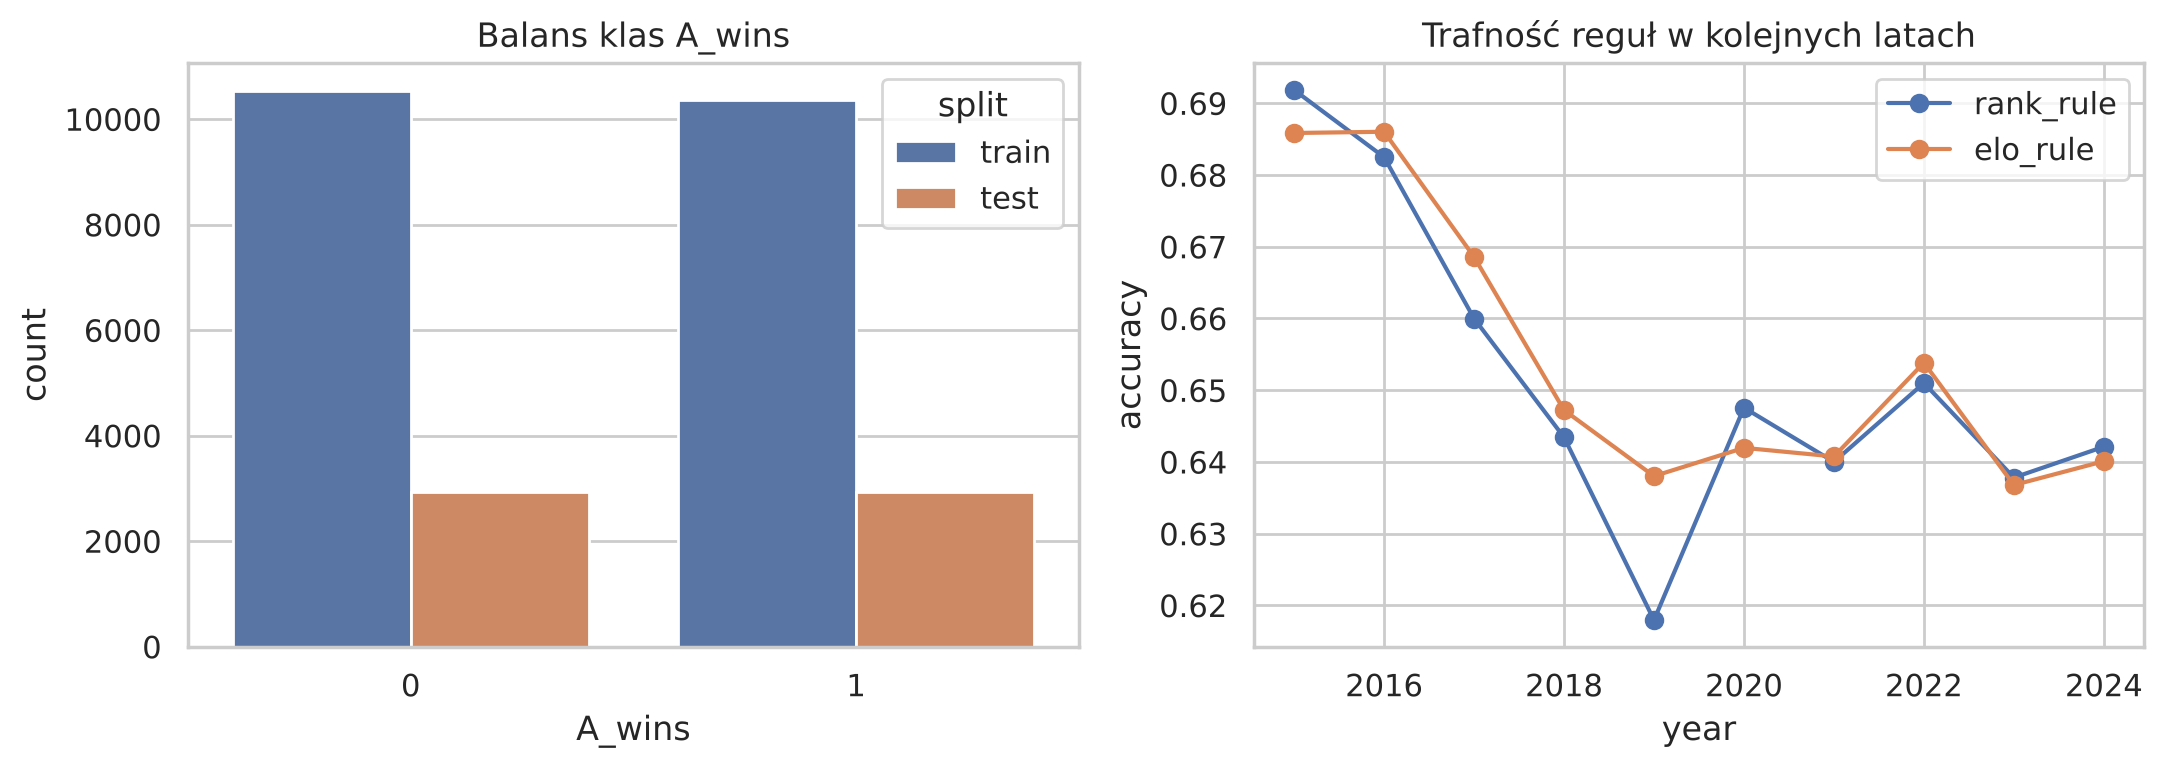

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="A_wins", hue="split", ax=ax[0])
ax[0].set_title("Balans klas A_wins")

# dla każdego meczu: czy reguła trafiła (True/False), potem średnia w roku = accuracy
year_acc = (
    df.assign(rank_rule=(df["A_rank"] < df["B_rank"]).astype(int) == df["A_wins"],
              elo_rule=(df["elo_diff"] > 0).astype(int) == df["A_wins"])
    .groupby("year")[["rank_rule", "elo_rule"]].mean()
)
year_acc.plot(marker="o", ax=ax[1])
ax[1].set_title("Trafność reguł w kolejnych latach")
ax[1].set_ylabel("accuracy")
plt.tight_layout()
plt.show()

**Wynik:** klasy są zbalansowane w obu zbiorach. Przewidywalność tenisa spada w czasie: reguła rankingowa trafiała w ok. 69% meczów w 2015 r., a w 2024 r. już tylko w ok. 64% (prawdopodobnie efekt zmiany pokoleniowej po erze Federera, Nadala i Djokovicia).

In [21]:
def rule_accuracy(mask):
    """Accuracy prostych reguł na wybranym podzbiorze meczów."""
    d = df[mask]
    return pd.Series({
        "lepszy ranking": ((d["A_rank"] < d["B_rank"]).astype(int) == d["A_wins"]).mean(),
        "wyższe Elo": ((d["elo_diff"] > 0).astype(int) == d["A_wins"]).mean(),
        "liczba meczów": len(d),
    })


pd.DataFrame({"całość": rule_accuracy(df["year"] > 0),
              "train": rule_accuracy(is_train),
              "test": rule_accuracy(~is_train)}).round(3)

,całość,train,test
lepszy ranking,0.652,0.655,0.640
wyższe Elo,0.655,0.659,0.638
liczba meczów,26759.000,20898.000,5861.000


**Wynik:** baseline rankingowy trafia w **64,0%** meczów testowych i to jest próg do pobicia. Samo Elo jest prawie tak dobre jak ranking ATP.

### 7.2 Test symetrii

Jeśli losowanie A/B było poprawne, to gdy A wygrał (`A_wins = 1`), A powinien mieć średnio lepszy ranking (ujemny `log_rank_diff`), wyższe Elo i lepszą formę, a gdy przegrał, dokładnie na odwrót, z podobną wielkością.

In [22]:
df.groupby("A_wins")[["log_rank_diff", "elo_diff", "form_diff", "h2h_diff"]].mean().round(3)

,log_rank_diff,elo_diff,form_diff,h2h_diff
A_wins,,,,
0,0.543,-77.497,-0.057,-0.230
1,-0.567,79.862,0.058,0.245


**Wynik:** wartości w obu wierszach są prawie lustrzanym odbiciem, więc losowanie zadziałało i nie zostało żadne ukryte powiązanie roli z wynikiem.

### 7.3 Test „ślepoty na przyszłość”

Najmocniejszy test na wyciek czasowy: liczymy cechy historyczne jeszcze raz, ale **tylko na danych do końca 2019 r.** Jeżeli jakaś cecha meczu z 2019 r. korzysta z przyszłości, to jej wartość się zmieni, bo przyszłych meczów nie ma w danych. Wszystkie wartości muszą być identyczne.

In [23]:
def history_features(played_df):
    """Ta sama logika co w punkcie 3, zamknięta w funkcji, żeby uruchomić ją na innych danych."""
    lg = pd.concat([player_rows(played_df, "winner", "loser", 1), player_rows(played_df, "loser", "winner", 0)])
    lg = lg.replace([np.inf, -np.inf], np.nan).sort_values(["player_id", "match_id"]).reset_index(drop=True)
    g = lg.groupby("player_id")
    lg["n_prev"] = g.cumcount()
    lg["form10"] = g["win"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
    lg["serve_avg"] = g["serve_won"].transform(lambda s: s.shift(1).rolling(20, min_periods=3).mean())
    gs = lg.groupby(["player_id", "surface"])["win"]
    sw = gs.transform(lambda s: s.shift(1).rolling(20, min_periods=1).sum()).fillna(0)
    sn = gs.transform(lambda s: s.shift(1).rolling(20, min_periods=1).count()).fillna(0)
    lg["surface_wr"] = (sw + PRIOR_N * 0.5) / (sn + PRIOR_N)
    lg["h2h_wins"] = lg.groupby(["player_id", "opp_id"])["win"].transform(lambda s: s.shift(1).cumsum()).fillna(0)
    lg["matches_14d"] = lg.groupby("player_id", group_keys=False)["tourney_date"].apply(matches_last_14d)
    return lg


check_cols = ["n_prev", "form10", "serve_avg", "surface_wr", "h2h_wins", "matches_14d"]
cut = played[played["year"] <= 2019]   # dane ucięte: bez meczów od 2020 r.

# cechy meczów z 2019 r.: z pełnych danych i z danych uciętych
full_2019 = long[long["tourney_date"].dt.year == 2019].set_index(["match_id", "player_id"])[check_cols]
cut_2019 = history_features(cut)
cut_2019 = cut_2019[cut_2019["tourney_date"].dt.year == 2019].set_index(["match_id", "player_id"])[check_cols]

# to samo dla Elo
elo_cut = compute_elo(cut.sort_values("match_id")).set_index("match_id")
elo_full = elo.set_index("match_id").loc[elo_cut.index]

pd.Series({
    "cechy historyczne identyczne": full_2019.sort_index().equals(cut_2019.sort_index()),
    "Elo identyczne": np.allclose(elo_full.values, elo_cut.values),   # porównanie z tolerancją na zaokrąglenia
})

cechy historyczne identyczne    True
Elo identyczne                  True
dtype: bool

**Wynik:** oba testy dają `True`. To mocniejszy dowód niż samo „użyliśmy `shift(1)`”: **żadna** cecha nie zależy od meczów rozegranych później.

### 7.4 Test „czy wynik nie jest za dobry”

To jeszcze nie modelowanie (to kolejna część projektu), tylko kontrola: prosta regresja logistyczna na cechach liczbowych, uczona na 2015–2022 i sprawdzona na 2023–2024. Wynik w okolicach 65–70% jest realistyczny. Wynik powyżej 80% oznaczałby, że do cech przeciekła informacja o wyniku meczu.

In [24]:
X_train, y_train = df.loc[is_train, NUM_FEATURES], df.loc[is_train, TARGET]
X_test, y_test = df.loc[~is_train, NUM_FEATURES], df.loc[~is_train, TARGET]

# skaler w pipeline: dopasowywany tylko na treningu
sanity = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
sanity.fit(X_train, y_train)
proba = sanity.predict_proba(X_test)[:, 1]   # prawdopodobieństwo, że wygra A
print(f"Test 2023–2024: accuracy = {accuracy_score(y_test, proba > 0.5):.3f}, AUC = {roc_auc_score(y_test, proba):.3f}")

Test 2023–2024: accuracy = 0.660, AUC = 0.726


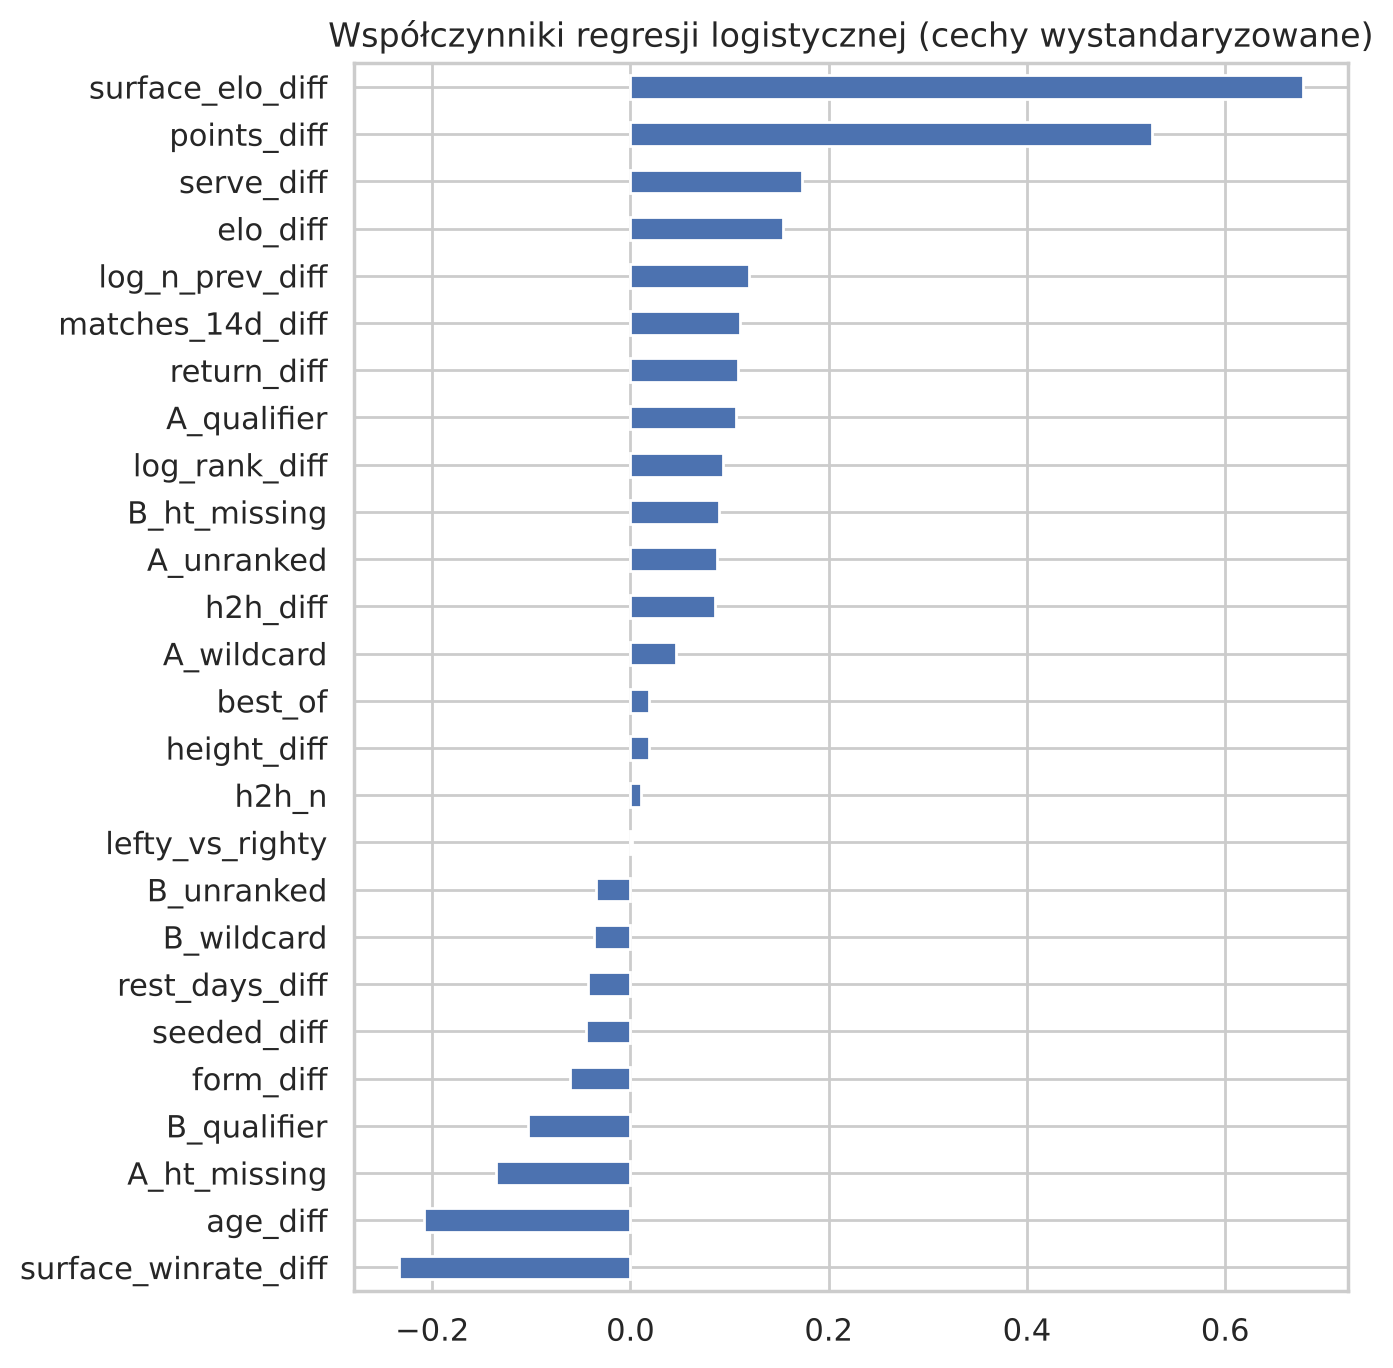

In [25]:
coefs = pd.Series(sanity[-1].coef_[0], index=NUM_FEATURES).sort_values()
coefs.plot.barh(figsize=(7, 7), title="Współczynniki regresji logistycznej (cechy wystandaryzowane)")
plt.tight_layout()
plt.show()

**Wynik:** accuracy 66,0% i AUC 0,726 na teście wobec 64,0% baseline'u. To realistyczny zysk, bez śladu wycieku.

**Uwaga do interpretacji współczynników:** największe wagi mają `surface_elo_diff` i `points_diff`, a `log_rank_diff` ma mały **dodatni** współczynnik, choć sam w sobie gorszy ranking A obniża jego szanse. To efekt **współliniowości**: ranking, punkty i oba Elo mierzą prawie to samo (siłę gracza), więc model rozdziela ich wpływ w sposób nieintuicyjny i znaki pojedynczych współczynników nie nadają się do interpretacji. Z tego samego powodu ujemny wychodzi `surface_winrate_diff`. W części modelowej warto pokazać macierz korelacji i użyć regularyzacji (Elastic Net), która część z tych cech wyzeruje.

## 8. Zapis gotowego zbioru

Zapisujemy identyfikatory (do analizy segmentów i podglądu), kontekst meczu, surowe wartości A/B, cechy porównawcze, flagi, cel i kolumnę `split`. Zbiór jest posortowany chronologicznie (`match_id`), więc nadaje się do `TimeSeriesSplit`.

In [26]:
ID_COLS = ["match_id", "tourney_id", "tourney_name", "tourney_date", "year", "split",
           "A_id", "A_name", "B_id", "B_name"]
CONTEXT_COLS = ["surface", "tourney_level", "round", "best_of", "draw_size", "davis_cup"]
RAW_AB = [f"{p}_{c}" for c in ["rank", "rank_points", "age", "ht", "hand", "elo", "surface_elo", "form10",
                                "surface_wr", "n_prev", "matches_14d", "days_since_last_tourney",
                                "serve_avg", "return_avg"] for p in ["A", "B"]]
DIFF_COLS = ["rank_diff", "log_rank_diff", "points_diff", "elo_diff", "surface_elo_diff", "age_diff",
             "height_diff", "form_diff", "surface_winrate_diff", "h2h_diff", "h2h_n", "rest_days_diff",
             "matches_14d_diff", "serve_diff", "return_diff", "log_n_prev_diff", "seeded_diff", "lefty_vs_righty"]
FLAG_COLS = [f"{p}_{c}" for c in ["unranked", "ht_missing", "seeded", "qualifier", "wildcard"] for p in ["A", "B"]]

out_cols = list(dict.fromkeys(ID_COLS + CONTEXT_COLS + RAW_AB + DIFF_COLS + FLAG_COLS + [TARGET]))   # bez duplikatów
final = df[out_cols].sort_values("match_id").reset_index(drop=True)
final.to_csv("dane/atp_cechy_2015_2024.csv", index=False, float_format="%.5g")   # 5 cyfr znaczących
print(final.shape)
final.head()

(26759, 73)


,match_id,tourney_id,tourney_name,tourney_date,year,split,A_id,A_name,B_id,B_name,surface,tourney_level,round,best_of,draw_size,davis_cup,A_rank,B_rank,A_rank_points,B_rank_points,A_age,B_age,A_ht,B_ht,A_hand,B_hand,A_elo,B_elo,A_surface_elo,B_surface_elo,...,B_return_avg,rank_diff,log_rank_diff,points_diff,elo_diff,surface_elo_diff,age_diff,height_diff,form_diff,surface_winrate_diff,h2h_diff,h2h_n,rest_days_diff,matches_14d_diff,serve_diff,return_diff,log_n_prev_diff,seeded_diff,lefty_vs_righty,A_unranked,B_unranked,A_ht_missing,B_ht_missing,A_seeded,B_seeded,A_qualifier,B_qualifier,A_wildcard,B_wildcard,A_wins
0,14899,2015-339,Brisbane,2015-01-04,2015,train,105733,Rhyne Williams,105357,John Millman,Hard,A,R32,3,28,0,220.0,153.0,221.0,328.0,23.7,25.5,185.0,183.0,R,R,1453.595454,1420.011837,1468.486823,1421.653645,...,0.358035,67.0,0.363190,-0.393380,33.583616,46.833178,-1.8,2.0,-0.022222,-0.036630,0.0,0,-93.0,0,0.013047,-0.037345,0.916291,0,0,0,0,0,0,0,0,1,0,0,1,0
1,14900,2015-339,Brisbane,2015-01-04,2015,train,103813,Jarkko Nieminen,106045,Denis Kudla,Hard,A,R32,3,28,0,73.0,123.0,689.0,440.0,33.4,22.3,185.0,180.0,L,R,1640.783971,1450.713789,1604.884161,1353.035968,...,0.342683,-50.0,-0.521725,0.447647,190.070182,251.848192,11.1,5.0,0.200000,0.240000,0.0,0,-119.0,0,0.038999,0.009776,1.934860,0,1,0,0,0,0,0,0,0,1,0,0,1
2,14901,2015-339,Brisbane,2015-01-04,2015,train,104468,Gilles Simon,105902,James Duckworth,Hard,A,R32,3,28,0,21.0,125.0,1730.0,430.0,30.0,22.9,183.0,183.0,R,R,1782.497905,1404.170243,1787.746617,1400.793779,...,0.307936,-104.0,-1.783791,1.390346,378.327662,386.952838,7.1,0.0,0.500000,0.239091,1.0,1,-35.0,0,0.006748,0.074648,2.484907,1,0,0,0,0,0,1,0,0,0,0,1,0
3,14902,2015-339,Brisbane,2015-01-04,2015,train,104979,Andrey Golubev,104871,Jeremy Chardy,Hard,A,R32,3,28,0,72.0,31.0,691.0,1195.0,27.4,27.8,180.0,188.0,R,R,1515.742563,1717.140402,1535.132193,1675.744299,...,0.363561,41.0,0.842679,-0.547152,-201.397839,-140.612106,-0.4,-8.0,-0.300000,-0.120000,1.0,1,7.0,0,-0.061062,-0.015735,-0.576784,0,0,0,0,0,0,0,0,0,0,0,0,0
4,14903,2015-339,Brisbane,2015-01-04,2015,train,105373,Martin Klizan,103781,Jurgen Melzer,Hard,A,R32,3,28,0,34.0,110.0,1094.0,505.0,25.4,33.6,191.0,183.0,L,L,1778.452690,1632.283944,1625.582069,1626.796032,...,0.350564,-76.0,-1.174120,0.771973,146.168747,-1.213963,-8.2,8.0,0.000000,0.080000,-1.0,1,7.0,0,0.016131,0.014190,-0.729079,0,0,0,0,0,0,0,0,0,0,0,0,1


Wczytanie zbioru w kolejnych notatnikach:

```python
df = pd.read_csv("dane/atp_cechy_2015_2024.csv", parse_dates=["tourney_date"])
train, test = df[df["split"] == "train"], df[df["split"] == "test"]
```

## 9. Podsumowanie i wnioski

**Co zrobiliśmy:**
* Z 42 571 meczów ATP z lat 2010–2024 zbudowaliśmy zbiór **26 759 meczów z lat 2015–2024** z **31 cechami** przedmeczowymi i zbalansowaną zmienną celu `A_wins` (49,7% / 50,3%).
* Usunęliśmy 913 meczów niedokończonych (krecze, walkowery, dyskwalifikacje) i poprawiliśmy błędne wzrosty (3, 15, 71 cm).
* Zbudowaliśmy cechy historyczne (forma, wyniki na nawierzchni, H2H, zmęczenie, statystyki serwisu i returnu) oraz ranking Elo, korzystając z historii od 2010 r., żeby uniknąć zimnego startu.
* Podzieliliśmy dane czasowo: trening 2015–2022 (20 898 meczów), test 2023–2024 (5 861 meczów).

**Jak zabezpieczyliśmy się przed wyciekiem danych:**

| Ryzyko | Rozwiązanie |
|---|---|
| Cel zaszyty w kolumnach `winner`/`loser` | Losowe role A/B, cel `A_wins` |
| Wynik i statystyki bieżącego meczu | Usunięcie `score`, `minutes`, `w_*`, `l_*`; statystyki tylko jako średnie z wcześniejszych meczów |
| Cechy „podglądające” przyszłość | `shift(1)` w cechach kroczących, Elo zapisywane przed aktualizacją, test na danych uciętych na 2019 r. |
| Informacja z testu w imputacji | Mediany liczone tylko na treningu |
| Uczenie na przyszłości | Podział czasowy zamiast losowego |

**Najważniejsze obserwacje:**
* Baseline „wygrywa lepszy w rankingu” trafia w **64,0%** meczów testowych, a reguła oparta na Elo w 63,8%.
* Przewidywalność tenisa spada w czasie (z ok. 69% w 2015 r. do ok. 64% w 2024 r.).
* Prosta regresja logistyczna na naszych cechach daje **66,0% accuracy i AUC 0,726** na teście, czyli realistyczny zysk ok. 2 p.p. nad baseline'em bez oznak wycieku.
* Cechy opisujące siłę gracza (ranking, punkty, Elo) są silnie współliniowe, co trzeba uwzględnić przy interpretacji modeli liniowych.

**Ograniczenia:**
* `tourney_date` to data rozpoczęcia turnieju, więc przerwę mierzymy między turniejami, a nie między meczami.
* Statystyk serwisowych brakuje w ok. 4% meczów (głównie Puchar Davisa); uzupełniamy je medianą.
* Gracze z krótką historią mają mniej wiarygodne cechy; łagodzimy to wygładzaniem, cechą `log_n_prev_diff` i rozgrzewką od 2010 r.